<a href="https://colab.research.google.com/github/joaocanaslopes/APP_FIELD/blob/main/Albumentations_hackthon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os

zip_filename = 'BD_fotos.zip'
extract_path = '.'

if os.path.exists(zip_filename):
    print("📦 A descomprimir o ficheiro ZIP...")
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("✅ Descompactado com sucesso!")
else:
    print(f"⚠️ O ficheiro '{zip_filename}' não foi encontrado. Certifica-te de que o carregaste para o painel esquerdo do Colab.")

📦 A descomprimir o ficheiro ZIP...
✅ Descompactado com sucesso!


In [3]:
import os
import cv2
import numpy as np
import math

# Instalar bibliotecas necessárias se não estiverem presentes
!pip install -q albumentations opencv-python
import albumentations as A

# Como os ficheiros foram descompactados na raiz, mudamos o caminho base para '.'
input_base_dir = '.'
output_base_dir = 'Dataset_Aumentado'

os.makedirs(output_base_dir, exist_ok=True)

# Pipeline de Data Augmentation
transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-30, 30), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.8),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.5),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
])

# DEFINIR O ALVO: Queremos que todas as classes fiquem com este número exato (ou muito próximo) de imagens
TARGET_IMAGES_PER_CLASS = 80

print(f"🚀 A iniciar o Data Augmentation com balanceamento dinâmico (Alvo: {TARGET_IMAGES_PER_CLASS} por classe)...")

classes_info = {
    'B': 26,
    'não nutricional': 24,
    'N': 14,
    'normal': 9,
    'P': 7,
    'K': 5
}

for class_name, orig_count in classes_info.items():
    input_class_dir = os.path.join(input_base_dir, class_name)
    output_class_dir = os.path.join(output_base_dir, class_name)

    os.makedirs(output_class_dir, exist_ok=True)

    if not os.path.exists(input_class_dir):
        print(f"⚠️ Aviso: A pasta '{class_name}' não foi encontrada em '{input_class_dir}'.")
        continue

    images = [img for img in os.listdir(input_class_dir) if img.lower().endswith(('.jpg', '.jpeg', '.png'))]
    num_images = len(images)

    if num_images == 0:
        print(f"⚠️ Aviso: Sem imagens válidas na pasta '{class_name}'.")
        continue

    # Calcular quantas augmentations fazer por cada imagem para atingir o target
    augmentations_per_image = math.ceil((TARGET_IMAGES_PER_CLASS - num_images) / num_images)
    if augmentations_per_image < 0:
        augmentations_per_image = 0

    count = 0

    for img_name in images:
        img_path = os.path.join(input_class_dir, img_name)
        image = cv2.imread(img_path)

        if image is None:
            continue

        base_name, ext = os.path.splitext(img_name)

        # Guardar original
        cv2.imwrite(os.path.join(output_class_dir, f"{base_name}_orig{ext}"), image)
        count += 1

        # Gerar o número calculado de imagens aumentadas
        for i in range(augmentations_per_image):
            augmented = transform(image=image)
            aug_image = augmented['image']

            output_filename = os.path.join(output_class_dir, f"{base_name}_aug_{i}{ext}")
            cv2.imwrite(output_filename, aug_image)
            count += 1

    print(f"✅ Classe '{class_name}': {num_images} originais -> {count} imagens geradas.")

print("\n🎉 Processo concluído! O dataset está perfeitamente equilibrado na pasta 'Dataset_Aumentado'.")

🚀 A iniciar o Data Augmentation com balanceamento dinâmico (Alvo: 80 por classe)...
✅ Classe 'B': 26 originais -> 104 imagens geradas.
✅ Classe 'não nutricional': 24 originais -> 96 imagens geradas.
✅ Classe 'N': 14 originais -> 84 imagens geradas.
✅ Classe 'normal': 9 originais -> 81 imagens geradas.
✅ Classe 'P': 7 originais -> 84 imagens geradas.
✅ Classe 'K': 5 originais -> 80 imagens geradas.

🎉 Processo concluído! O dataset está perfeitamente equilibrado na pasta 'Dataset_Aumentado'.



📸 --- Classe: B ---


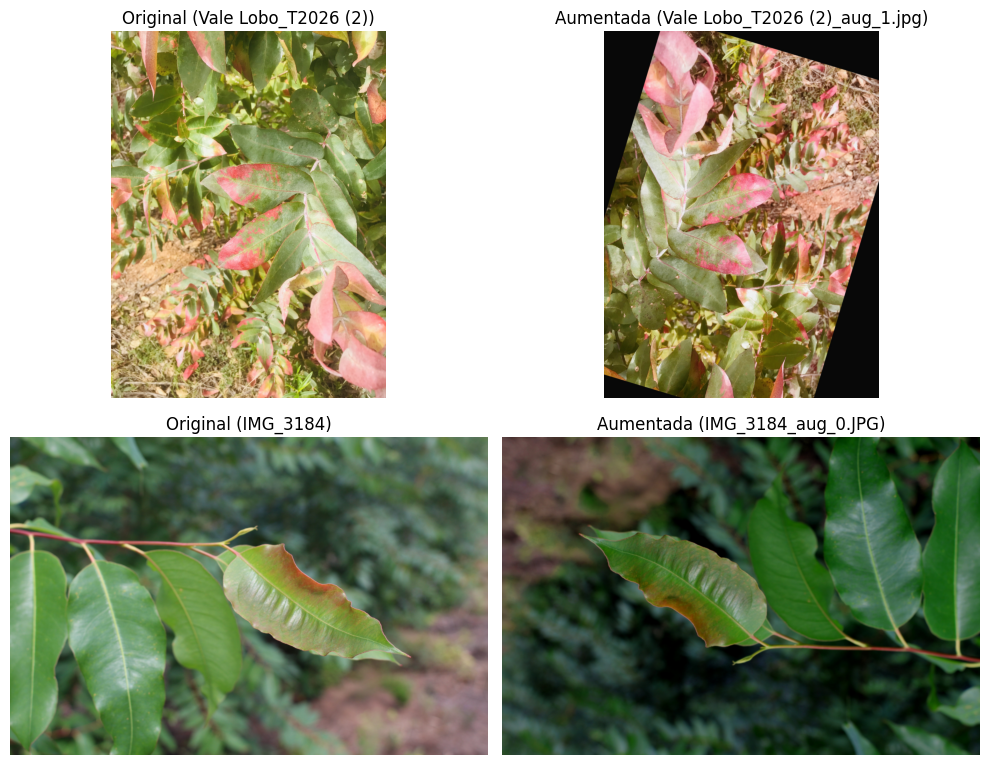


📸 --- Classe: não nutricional ---


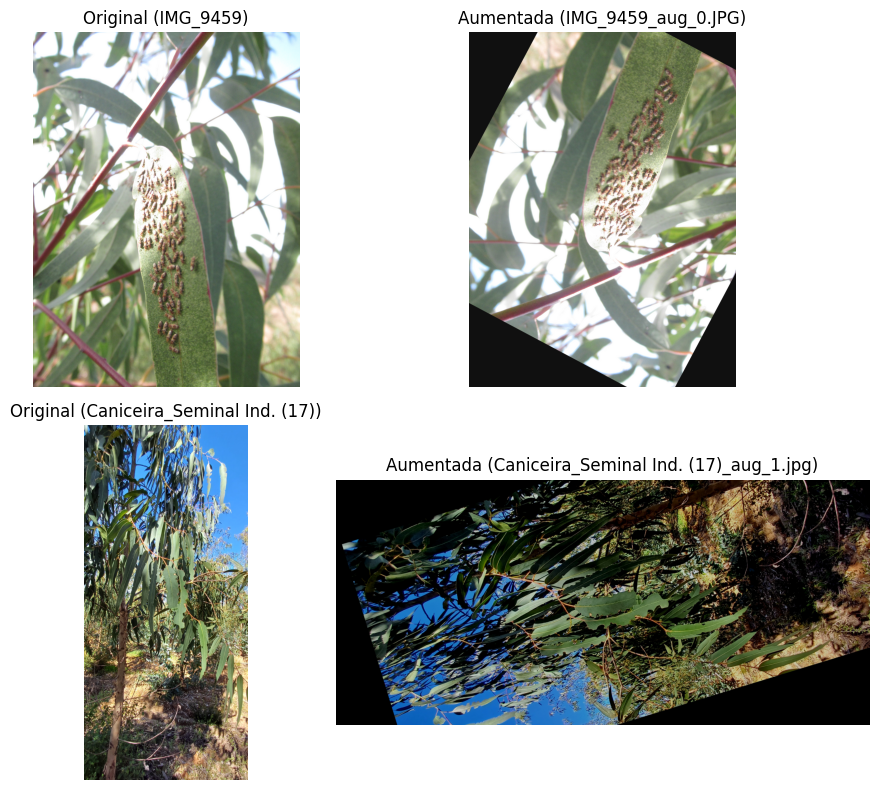


📸 --- Classe: N ---


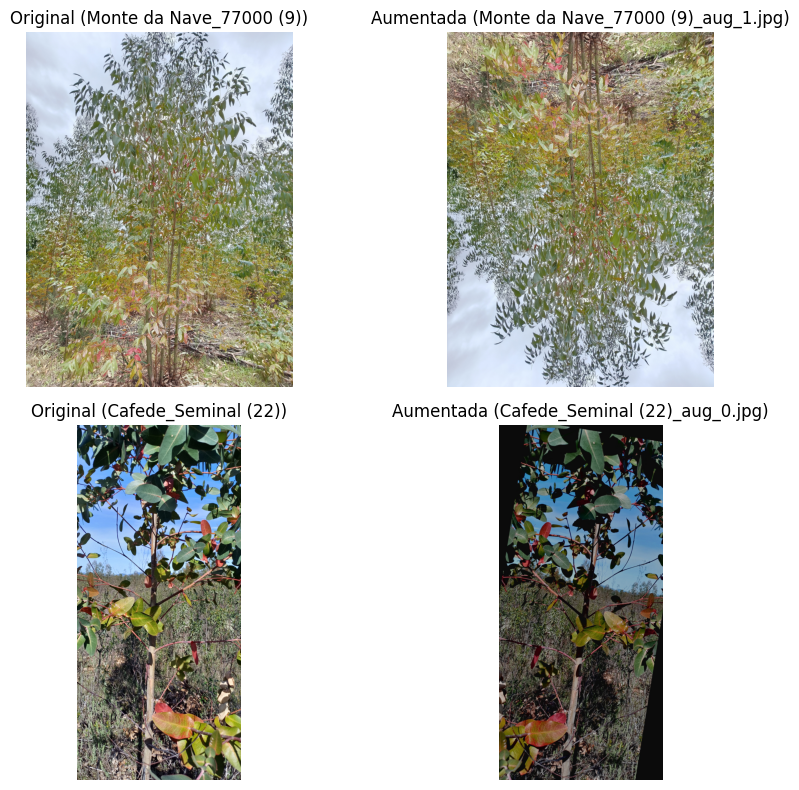


📸 --- Classe: normal ---


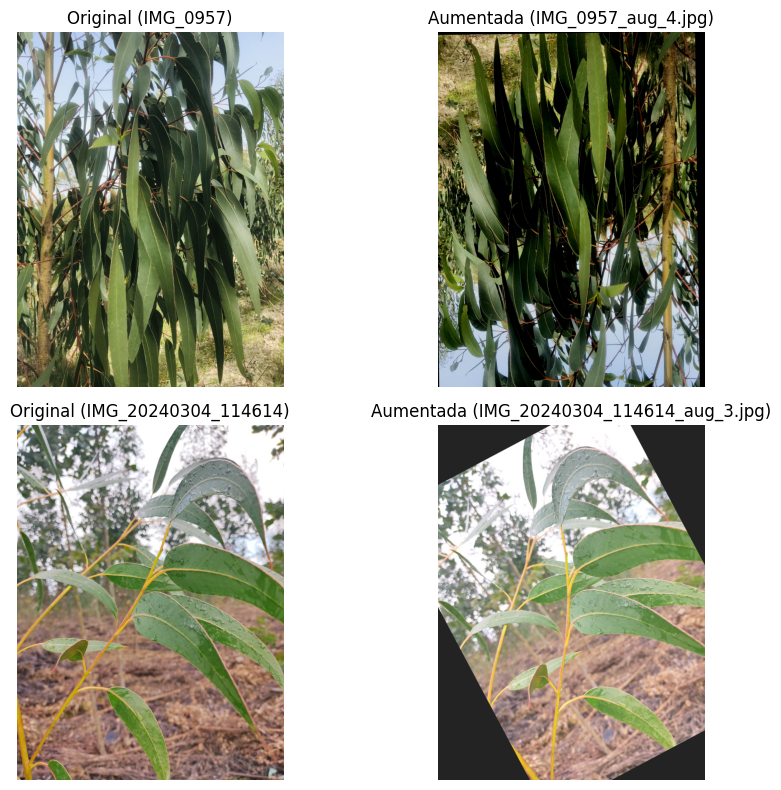


📸 --- Classe: P ---


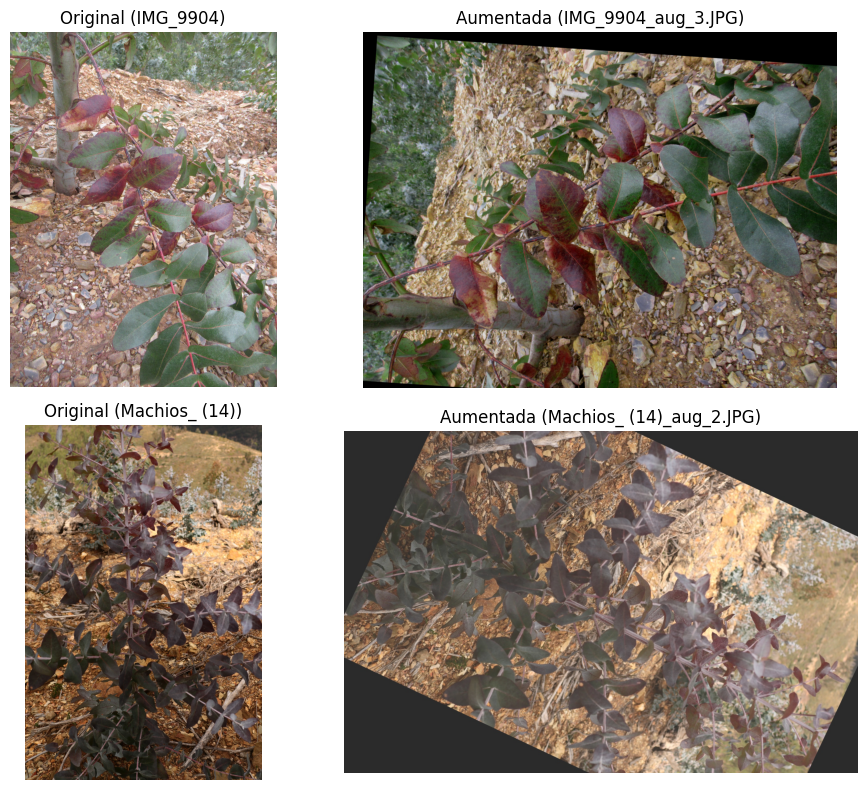


📸 --- Classe: K ---


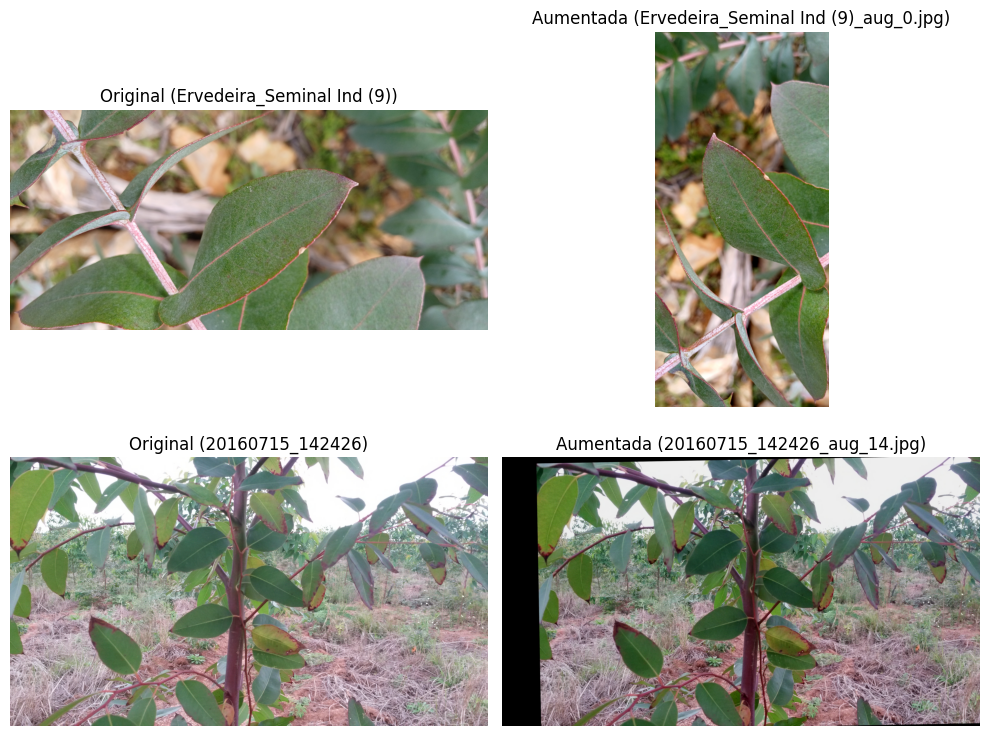

In [4]:
import os
import glob
import cv2
import matplotlib.pyplot as plt

output_base_dir = 'Dataset_Aumentado'
classes = ['B', 'não nutricional', 'N', 'normal', 'P', 'K']

for class_name in classes:
    class_path = os.path.join(output_base_dir, class_name)
    if not os.path.exists(class_path):
        continue

    # Encontrar todas as imagens originais na pasta desta classe
    orig_images = glob.glob(os.path.join(class_path, "*_orig.*"))

    if len(orig_images) < 2:
        print(f"⚠️ Não há originais suficientes na classe '{class_name}' para mostrar 2 pares.")
        continue

    print(f"\n📸 --- Classe: {class_name} ---")

    # Configurar uma figura com 2 linhas (uma para cada par) e 2 colunas (Original vs Aumentada)
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    pairs_shown = 0
    for orig_path in orig_images:
        if pairs_shown >= 2:
            break

        # Extrair o nome base para encontrar a versão aumentada correspondente
        base_name = os.path.basename(orig_path).split('_orig')[0]

        # Procurar por qualquer imagem aumentada que comece com o mesmo nome base
        aug_pattern = os.path.join(class_path, f"{base_name}_aug_*")
        aug_images = glob.glob(aug_pattern)

        if not aug_images:
            continue

        aug_path = aug_images[0] # Pegamos no primeiro exemplo aumentado encontrado

        # Carregar as imagens (e converter de BGR para RGB para o matplotlib exibir corretamente)
        img_orig = cv2.imread(orig_path)
        img_aug = cv2.imread(aug_path)

        if img_orig is None or img_aug is None:
            continue

        img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
        img_aug = cv2.cvtColor(img_aug, cv2.COLOR_BGR2RGB)

        # Mostrar Original
        axes[pairs_shown, 0].imshow(img_orig)
        axes[pairs_shown, 0].set_title(f"Original ({base_name})")
        axes[pairs_shown, 0].axis('off')

        # Mostrar Aumentada
        axes[pairs_shown, 1].imshow(img_aug)
        axes[pairs_shown, 1].set_title(f"Aumentada ({os.path.basename(aug_path)})")
        axes[pairs_shown, 1].axis('off')

        pairs_shown += 1

    plt.tight_layout()
    plt.show()

In [5]:
import os
import shutil
from google.colab import files
import ipywidgets as widgets
from IPython.display import display

# Nome do ficheiro ZIP de saída
zip_name = 'Dataset_Aumentado.zip'
pasta_para_zipar = 'Dataset_Aumentado'

def criar_e_descarregar_zip(b):
    b.disabled = True
    b.description = 'A compactar... ⚙️'

    if os.path.exists(pasta_para_zipar):
        # Compacta a pasta
        shutil.make_archive(pasta_para_zipar, 'zip', pasta_para_zipar)
        b.description = 'A transferir... 💾'
        # Inicia o download no browser
        files.download(zip_name)
        b.description = 'Download Concluído! ✅'
    else:
        b.description = 'Erro: Pasta não encontrada! ❌'
        print(f"⚠️ A pasta '{pasta_para_zipar}' não foi encontrada na sessão do Colab.")

# Criar botão interativo
botao_download = widgets.Button(
    description='Descarregar Dataset (ZIP) 📥',
    disabled=False,
    button_style='success',
    tooltip='Clique para descarregar a pasta Dataset_Aumentado compactada',
    icon='download',
    layout=widgets.Layout(width='300px', height='50px')
)

botao_download.on_click(criar_e_descarregar_zip)
display(botao_download)

Button(button_style='success', description='Descarregar Dataset (ZIP) 📥', icon='download', layout=Layout(heigh…

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>